Week 5 notebook, support vector machines, the kernel trick, and regularization, Mike Hembree

Back to the classification version of the problem from Week 4, predicting whether an ICU stay ever gets a positive CAM-ICU delirium screen from age, gender, vitals, and total GCS. Same 140 stay MIMIC-IV demo table, 45 positives and 95 negatives. SVMs are very sensitive to feature scale and to the C parameter, so this is a good week to see how much tuning matters on a tiny dataset.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'


In [2]:
# load the feature table and fill the few missing values with the median
feat = pd.read_csv('delirium_features.csv')

rcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min', 'delirium_positive']
ccols = rcols[:-1]

data = feat[rcols + ['los']].copy()
for c in rcols:
    data[c] = data[c].fillna(data[c].median())

X = data[rcols]
y = data['los']
Xc = data[ccols]
yc = feat['delirium_positive'].fillna(0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)

cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 6, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
print(data.shape, yc.value_counts().to_dict())


(140, 11) {0: 95, 1: 45}


In [3]:
# baseline svms on the stratified holdout split, scaled features
from sklearn.svm import SVC

def hold(name, model):
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    score = model.decision_function(Xc_test)
    return {'model': name, 'accuracy': accuracy_score(yc_test, pred), 'precision': precision_score(yc_test, pred, zero_division = 0), 'recall': recall_score(yc_test, pred), 'f1': f1_score(yc_test, pred), 'auc': roc_auc_score(yc_test, score)}

pd.DataFrame([
    hold('linear svm', make_pipeline(StandardScaler(), SVC(kernel = 'linear'))),
    hold('rbf svm', make_pipeline(StandardScaler(), SVC(kernel = 'rbf'))),
    hold('polynomial svm', make_pipeline(StandardScaler(), SVC(kernel = 'poly', degree = 3))),
    hold('rbf svm unscaled', SVC(kernel = 'rbf')),
])


,model,accuracy,precision,recall,f1,auc
0,linear svm,0.678571,0.500000,0.333333,0.400000,0.783626
1,rbf svm,0.642857,0.333333,0.111111,0.166667,0.853801
2,polynomial svm,0.714286,1.000000,0.111111,0.200000,0.883041
3,rbf svm unscaled,0.678571,0.000000,0.000000,0.000000,0.742690


The holdout numbers are all over the place. The polynomial kernel has the best auc at 0.88 and the rbf kernel is at 0.85, but both catch only 1 of the 9 positive stays (recall 0.11), while the linear svm has the lowest auc of the scaled ones (0.78) and finds 3 of 9. Skipping the scaler drops the rbf svm to an auc of 0.74 and recall of zero, it just predicts everything negative. With 28 test stays I don't trust the auc ranking here, it's mostly noise from nine positives.

In [4]:
# grid search over C and gamma for the rbf kernel, five fold cv on the training rows
grid = {'svc__C': [0.1, 0.3, 1, 3, 10, 30, 100], 'svc__gamma': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}
gs = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'rbf', class_weight = 'balanced')), grid, scoring = 'roc_auc', cv = 5, n_jobs = 2)
gs.fit(Xc_train, yc_train)
print(gs.best_params_, round(gs.best_score_, 3))
tab = pd.DataFrame(gs.cv_results_).pivot_table(index = 'param_svc__C', columns = 'param_svc__gamma', values = 'mean_test_score')
tab.round(3)


{'svc__C': 30, 'svc__gamma': 0.01} 0.786


param_svc__gamma,0.001,0.003,0.010,0.030,0.100,0.300
param_svc__C,,,,,,
0.1,0.744,0.742,0.748,0.758,0.771,0.751
0.3,0.744,0.742,0.748,0.767,0.774,0.754
1.0,0.744,0.742,0.749,0.782,0.774,0.719
3.0,0.744,0.734,0.772,0.782,0.745,0.668
10.0,0.736,0.751,0.768,0.762,0.690,0.656
30.0,0.747,0.773,0.786,0.730,0.681,0.660
100.0,0.761,0.762,0.762,0.696,0.679,0.660


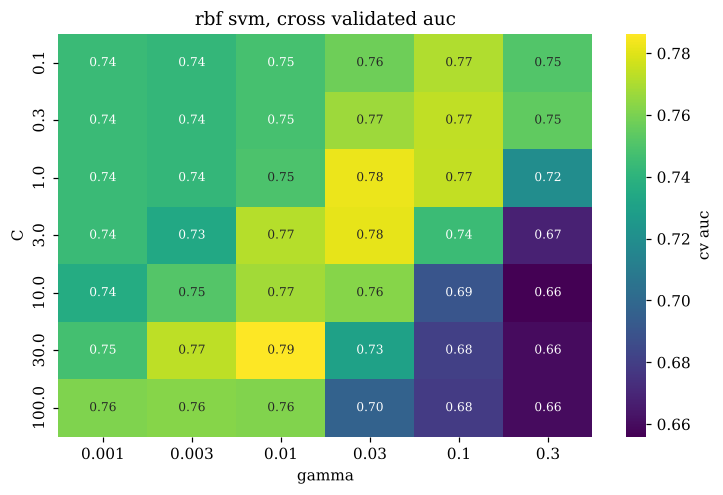

In [5]:
# figure, cv auc over the c and gamma grid
fig, ax = plt.subplots(figsize = (6.8, 4.6))
sns.heatmap(tab, annot = True, fmt = '.2f', cmap = 'viridis', ax = ax, cbar_kws = {'label': 'cv auc'}, annot_kws = {'size': 8})
ax.set_xlabel('gamma')
ax.set_ylabel('C')
ax.set_title('rbf svm, cross validated auc')
plt.tight_layout()
plt.savefig('figs/svm_grid.png', dpi = 200)
plt.show()


The grid is pretty flat. Cv auc stays between about 0.65 and 0.79 over the whole grid, the best spot is C of 30 with gamma of 0.01 (0.786), and large gamma with large C collapses toward 0.66, which is the classic overfit corner where the boundary wraps around individual stays.

In [6]:
# linear svm regularization strength, and the effect of class weights
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    for cw in [None, 'balanced']:
        m = make_pipeline(StandardScaler(), SVC(kernel = 'linear', C = C, class_weight = cw))
        r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = ('roc_auc', 'recall', 'f1'), n_jobs = 2)
        rows.append({'C': C, 'class weight': str(cw), 'auc': r['test_roc_auc'].mean(), 'recall': r['test_recall'].mean(), 'f1': r['test_f1'].mean()})
pd.DataFrame(rows).round(3)


,C,class weight,auc,recall,f1
0,0.001,None,0.757,0.000,0.000
1,0.001,balanced,0.733,1.000,0.486
2,0.010,None,0.758,0.000,0.000
3,0.010,balanced,0.733,0.756,0.630
4,0.100,None,0.758,0.348,0.435
5,0.100,balanced,0.753,0.785,0.634
6,1.000,None,0.756,0.489,0.521
7,1.000,balanced,0.750,0.748,0.624
8,10.000,None,0.755,0.496,0.522
9,10.000,balanced,0.749,0.741,0.615


Class weights barely change the auc but they change everything about recall. With no class weight the linear svm at small C predicts nothing positive at all (recall 0), and with balanced weights recall goes up to about 0.75 to 0.78 while f1 roughly doubles. For a screening problem that's the setting I'd actually use.

In [7]:
# nested cross validation for the tuned svms, tuning happens inside every outer fold
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
lin = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'linear', class_weight = 'balanced')), {'svc__C': [0.001, 0.01, 0.1, 1, 10]}, scoring = 'roc_auc', cv = 5)
rbf = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel = 'rbf', class_weight = 'balanced')), {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.001, 0.01, 0.03, 0.1, 0.3]}, scoring = 'roc_auc', cv = 5)
rows = []
for name, m in [('linear svm tuned', lin), ('rbf svm tuned', rbf)]:
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = scoring, n_jobs = 2)
    rows.append({'model': name, 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
svm_res = pd.DataFrame(rows)
svm_res.to_csv('figs/svm_results.csv', index = False)
svm_res.round(3)


,model,auc,auc sd,recall,precision,f1,accuracy
0,linear svm tuned,0.745,0.068,0.763,0.527,0.610,0.683
1,rbf svm tuned,0.754,0.073,0.867,0.510,0.625,0.638


Under nested cross validation the tuned linear svm gets an auc of 0.745 and the tuned rbf svm 0.754, with a fold to fold standard deviation around 0.07, so they're not distinguishable. The rbf version has the best recall (0.87) but the worst accuracy (0.64), it flags a lot of stays to avoid missing positives.